# **Electricity  Bill Prediction**

---



*   Project level: Beginner
*   Learning Mode: Theory + Google colab practical
*   Algorithm: Multiple Linear Regression
*   Input features: Monthy Hours, TariffRate
*   Target variable: Electricity Bill Price
*   Primary tools: Python,Pandas,Matplotlib,Scilit-learn

In [23]:
#Import the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

print("Libraries imported successfully")

Libraries imported successfully


In [24]:
#Loading the Dataset
df = pd.read_csv('/content/electricity_bill_dataset.csv')

print("Dataset loaded successfully")
print(df.head())

Dataset loaded successfully
   Fan  Refrigerator  AirConditioner  Television  Monitor  MotorPump  Month  \
0   16          23.0             2.0         6.0      1.0          0     10   
1   19          22.0             2.0         3.0      1.0          0      5   
2    7          20.0             2.0         6.0      7.0          0      7   
3    7          22.0             3.0        21.0      1.0          0      6   
4   11          23.0             2.0        11.0      1.0          0      2   

        City                                    Company  MonthlyHours  \
0  Hyderabad                    Tata Power Company Ltd.           384   
1   Vadodara                                       NHPC           488   
2     Shimla                            Jyoti Structure           416   
3     Mumbai                            Power Grid Corp           475   
4     Mumbai  Ratnagiri Gas and Power Pvt. Ltd. (RGPPL)           457   

   TariffRate  ElectricityBill  
0         8.4           3

In [25]:
#Inspect the dataset
print("First five rows:")
print(df.head())

print("Last five rows:")
print(df.tail())

print("\nDataset shape:")
print(df.shape)

print("\nDataset names:")
print(df.columns)

print("\nDataset info:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())


First five rows:
   Fan  Refrigerator  AirConditioner  Television  Monitor  MotorPump  Month  \
0   16          23.0             2.0         6.0      1.0          0     10   
1   19          22.0             2.0         3.0      1.0          0      5   
2    7          20.0             2.0         6.0      7.0          0      7   
3    7          22.0             3.0        21.0      1.0          0      6   
4   11          23.0             2.0        11.0      1.0          0      2   

        City                                    Company  MonthlyHours  \
0  Hyderabad                    Tata Power Company Ltd.           384   
1   Vadodara                                       NHPC           488   
2     Shimla                            Jyoti Structure           416   
3     Mumbai                            Power Grid Corp           475   
4     Mumbai  Ratnagiri Gas and Power Pvt. Ltd. (RGPPL)           457   

   TariffRate  ElectricityBill  
0         8.4           3225.6  
1  

In [26]:
# Check Data Quality

print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print(df['ElectricityBill'].describe())

Missing values:
Fan                0
Refrigerator       0
AirConditioner     0
Television         0
Monitor            0
MotorPump          0
Month              0
City               0
Company            0
MonthlyHours       0
TariffRate         0
ElectricityBill    0
dtype: int64

Duplicate Rows:
0
count    45345.000000
mean      4311.771307
std       1073.886406
min        807.500000
25%       3556.800000
50%       4299.400000
75%       5038.800000
max       8286.300000
Name: ElectricityBill, dtype: float64


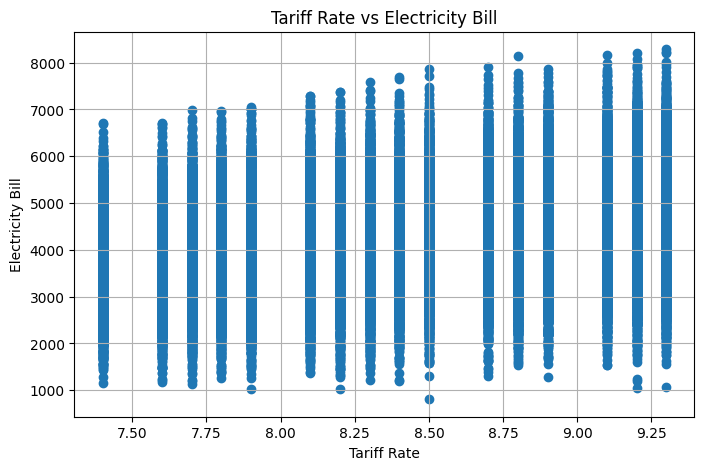

In [27]:
#Graph 1 — Monthly Hours vs Electricity Bill

plt.figure(figsize=(8, 5))

plt.scatter(df['TariffRate'], df['ElectricityBill'])

plt.xlabel('Tariff Rate')
plt.ylabel('Electricity Bill')
plt.title('Tariff Rate vs Electricity Bill')
plt.grid(True)

plt.show()

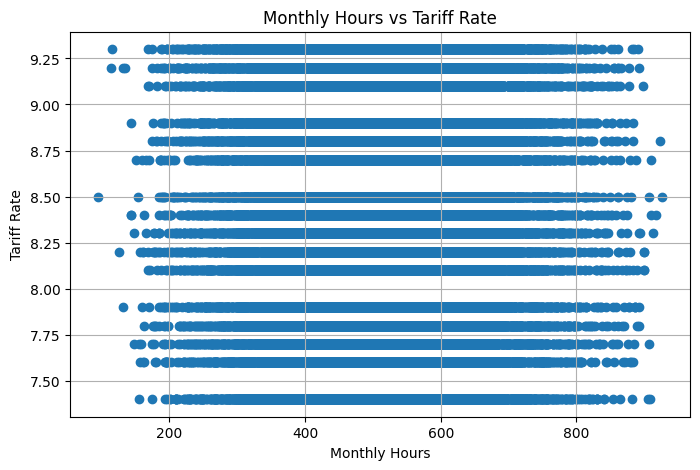

In [28]:
#Graph 2 — Tariff Rate vs Electricity Bill
plt.figure(figsize=(8, 5))

plt.scatter(df['MonthlyHours'], df['TariffRate'])

plt.xlabel('Monthly Hours')
plt.ylabel('Tariff Rate')
plt.title('Monthly Hours vs Tariff Rate')
plt.grid(True)

plt.show()

# **Preparing Data for Machine Learning**
**Seperate feature and target**

In [29]:
X = df[['MonthlyHours', 'TariffRate']]
y = df['ElectricityBill']

print("Input Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

Input Features:
   MonthlyHours  TariffRate
0           384         8.4
1           488         7.8
2           416         7.7
3           475         9.2
4           457         9.2

Target Values:
0    3225.6
1    3806.4
2    3203.2
3    4370.0
4    4204.4
Name: ElectricityBill, dtype: float64


In [30]:
#Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print("Training samples:",len(X_train))
print("Testing samples:",len(X_test))

Training samples: 36276
Testing samples: 9069


In [31]:
#Create the model
model=LinearRegression()

In [32]:
#Train the model
model.fit(X_train,y_train)

LinearRegression()

In [33]:
#Inspect learned parameters
print("Coefficients:")
print(model.coef_)

print("\nIntercept:")
print(model.intercept_)

Coefficients:
[  8.36988239 515.17026516]

Intercept:
-4311.17455092747


In [34]:
#Predict the test data
y_pred=model.predict(X_test)

print("Actual Electricity bill:")
print(y_test.values)

print("\nPredicted Electricity bill:")
print(y_pred)

Actual Electricity bill:
[5054.7 3809.2 3245.3 ... 5032.3 4672.9 5519.5]

Predicted Electricity bill:
[5033.70842621 3856.15047314 3237.3626655  ... 5090.28562808 4676.98243707
 5530.71044114]


In [35]:
#Compare Actual and predicted values
comparison=pd.DataFrame({
    "Actual Electricity Bill ":y_test.values,
    "Predicted Electricity Bill ":y_pred
    })
print(comparison)

      Actual Electricity Bill   Predicted Electricity Bill 
0                       5054.7                  5033.708426
1                       3809.2                  3856.150473
2                       3245.3                  3237.362666
3                       5728.8                  5724.515468
4                       4148.0                  4152.275311
...                        ...                          ...
9064                    3973.8                  3995.712256
9065                    4761.5                  4751.727889
9066                    5032.3                  5090.285628
9067                    4672.9                  4676.982437
9068                    5519.5                  5530.710441

[9069 rows x 2 columns]


In [36]:
#Mean Absolute Error
mae=mean_absolute_error(y_test,y_pred)
print("Mean Absolute Error:",mae)

Mean Absolute Error: 49.1847309882543


In [37]:
#Mean Squared Error
mse=mean_squared_error(y_test,y_pred)
print("Mean Squared Error:",mse)

Mean Squared Error: 4969.841882764399


In [38]:
#Root Mean Squared Error
rmse=np.sqrt(mse)
print("Root Mean Squared Error:",rmse)

Root Mean Squared Error: 70.49710549210087


In [39]:
#R2 Score
r2=r2_score(y_test,y_pred)
print("R2 Score:",r2)

R2 Score: 0.9956382665810525


In [40]:
#Predict Electricity Bill Price
monthly_hours = 300
tariff_rate = 8.5

new_data = pd.DataFrame({
    'MonthlyHours': [monthly_hours],
    'TariffRate': [tariff_rate]
})

predicted_bill = model.predict(new_data)

print("Monthly Hours:", monthly_hours)
print("Tariff Rate:", tariff_rate)
print("Predicted Electricity Bill: ₹", round(predicted_bill[0], 2))

Monthly Hours: 300
Tariff Rate: 8.5
Predicted Electricity Bill: ₹ 2578.74


In [41]:
difference = (
    df['ElectricityBill']
    - df['MonthlyHours'] * df['TariffRate']
).abs()

print("Maximum difference:", difference.max())

Maximum difference: 4.547473508864641e-13


In [42]:
print("Formula matches:", difference.max() < 0.000001)

Formula matches: True


In [43]:
import joblib
import sklearn
#Save the trained model
joblib.dump(model, "electricity_bill_prediction_model.pki")

#Check the installed scikit-learn version
print("Scikit-learn version:",sklearn.__version__)

print("Model saved successfully")

Scikit-learn version: 1.6.1
Model saved successfully


In [44]:
from google.colab import files
files.download("electricity_bill_prediction_model.pki")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>